# 26 · SeasFire: read the cube before reading the fire

**Time:** 35 minutes · **Audience:** undergraduate / introductory graduate GIS and Earth science.

**By the end:** inspect source Zarr metadata; distinguish observations, reanalysis and derived quantities; preserve missing coverage.

[Run in JupyterLite](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=26_seasfire_discovery.ipynb) · [Earth lab](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/) · [Sources and licenses](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/credits.html)

Run cells from top to bottom with **Shift+Enter**. The first kernel start downloads Python WebAssembly packages.
The bundled exercises need no data-service account. Save a copy with **File → Save and Export Notebook As** before clearing browser storage.

![Four-stage workflow: STAC discovery, Zarr reading, SQL selection, linked views](assets/pipeline.svg)

In [1]:
from course import *
import numpy as np
import matplotlib.pyplot as plt
print('Ready: Python + NumPy + local teaching data')

Ready: Python + NumPy + local teaching data


## 1. One grid, several kinds of evidence

SeasFire harmonizes historical Earth-system variables for fire research. This studio uses the **v0.4**
release on ESA EarthCODE: **2001–2021**, nominal **8-day** intervals and **0.25°** grid cells.
Harmonization makes arrays align; it does not make their original sensors, accuracy or temporal support identical.

![SeasFire teaching workflow: catalog, bounded windows, masks and units, SQL and LexCube, cautious interpretation](assets/seasfire-workflow.svg)

| Variable | What it represents | Unit / aggregation |
|---|---|---|
| `gwis_ba` | Historical GWIS burned-area estimates, allocated by ignition date | hectares per cell and period; summed |
| `tp` | ERA5 total precipitation | mm per period; summed |
| `t2m_mean` | ERA5 2 m air temperature | kelvin; mean |
| `vpd` | SeasFire-derived vapor pressure deficit | hPa; mean |
| `ndvi` | Harmonized MODIS MOD13C1 v6 vegetation index | dimensionless; mean |

**Predict:** which variable can be summed across cells, and which should be area-weighted?
Our windows include northern Ghana and neighboring countries, and central Zambia and neighboring areas.
They are selected teaching windows, not country statistics.

In [2]:
from seasfire import load_seasfire, raster
d=load_seasfire('ghana')
print(d['region']['title'])
print('Axes: time, latitude, longitude:',d['gwis_ba'].shape)
print('First / last starts:',d['dates'][[0,-1]])
print('Interval lengths and counts:',np.unique(d['duration_days'],return_counts=True))
print('Pixel-edge bounds:',d['region']['bounds'])
print('Source version:',d['provenance']['version'],'|',d['provenance']['license'])

Northern Ghana and neighboring savannas
Axes: time, latitude, longitude: (966, 16, 16)
First / last starts: ['2001-01-01' '2021-12-27']
Interval lengths and counts: (array([5, 6, 8]), array([ 16,   5, 945]))
Pixel-edge bounds: [-5.25, 7.75, -1.25, 11.75]
Source version: 0.4 | CC-BY-4.0


## 2. A small selection can require a large source chunk

Read the real Zarr v2 metadata before opening a remote array. The source stores an entire time axis in
each spatial chunk. A 16 × 16 request may still decode a 966 × 180 × 360 chunk. The native preparation
script caps source requests at 1.5 GiB in total, caches the necessary objects, and records their hashes.
The notebook reads a small local NPZ; the linked SQL lab reads an uncompressed Zarr v2 repackaging.
Both retain native grid values. No full global archive is loaded into your browser.

In [3]:
spec=d['metadata']['gwis_ba/.zarray']
print('Global shape:',spec['shape'],'| chunks:',spec['chunks'],'| codec:',spec['compressor'])
print('One decoded source chunk: %.1f MiB' % (np.prod(spec['chunks'])*4/1024**2))
print('Selected raw fire array: %.2f MiB' % (d['gwis_ba'].nbytes/1024**2))
print('Latitude descends:',bool(np.all(np.diff(d['lat'])<0)))
print('Raw source description:',d['metadata']['gwis_ba/.zattrs']['creator_notes'])

Global shape: [966, 720, 1440] | chunks: [966, 180, 360] | codec: {'blocksize': 0, 'clevel': 5, 'cname': 'lz4', 'id': 'blosc', 'shuffle': 1}
One decoded source chunk: 238.8 MiB
Selected raw fire array: 0.94 MiB
Latitude descends: True
Raw source description: The missing data for the year 2001 has been filled with NaN values. The dataset is constructed using the ignition dates of the burned areas shapefiles. Each year is divided into 46 periods of 8 days, with the last period in December consisting of either 5 or 6 days, depending on whether it is a leap year.


## 3. Missing is not zero

The GWIS temporal availability mask marks 2001 unavailable. It is a **global time-coverage mask**,
not a pixel-level quality score. The helper keeps those values missing. A finite zero later in the record
means zero burned area in this harmonized product, not proof that no small fire occurred.

The final annual interval has only 5 or 6 days. Derive durations from the actual timestamps and the
2022-01-01 closing boundary; do not assume 966 identical intervals or replace gaps with zero.

Unavailable bins: 46
Finite zero-fire cells: 188109


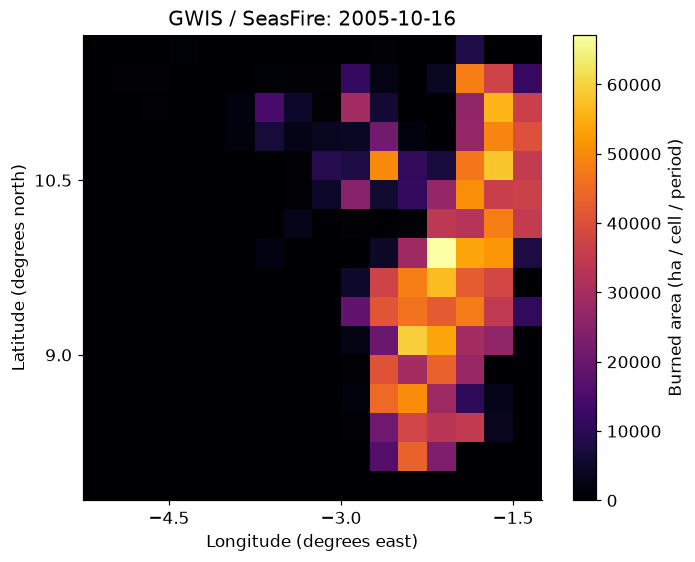

In [4]:
available=d['gwis_ba_valid_mask']==1
assert np.isnan(d['gwis_ba'][~available]).all()
print('Unavailable bins:',int((~available).sum()))
print('Finite zero-fire cells:',int(np.sum(d['gwis_ba']==0)))
t=int(np.nanargmax(np.nansum(d['gwis_ba'],axis=(1,2))))
fig,ax=plt.subplots(figsize=(7,5),layout='constrained')
im=raster(ax,d,d['gwis_ba'][t],f"GWIS / SeasFire: {d['dates'][t]}")
fig.colorbar(im,ax=ax,label='Burned area (ha / cell / period)')
plt.show()

## 4. Follow the catalog trail

Open the [ESA catalog item](https://opensciencedata.esa.int/products/seasfire-cube/item), then inspect its
Zarr asset, license and time coverage. Compare with the [versioned Zenodo record](https://doi.org/10.5281/zenodo.13834057).
The catalog and the mirror may evolve; this course records the exact retrieved object hashes.
An optional native refresh is `python scripts/prepare_seasfire.py --fetch` with `requirements-seasfire.txt`.
Do not run that command in JupyterLite.

## Try it yourself

Open the Zambia window. Compare its grid bounds and units. Explain why the same grid resolution does not imply the same accuracy for fire and precipitation.

## Check your reasoning

Resampling and harmonization align coordinates; uncertainty remains specific to the underlying product. Missing coverage must stay missing.

## Evidence journal

Write four sentences: **what I observed; how I calculated it; what this cannot establish; what evidence I need next**.
For any figure you reuse, retain its units, date or scenario, data origin, transformations, and attribution.

## Sources and credit

- [SeasFire Cube v0.4, Alonso et al. (2024)](https://doi.org/10.5281/zenodo.13834057), CC-BY-4.0. Spatial subsets and browser repackaging by this course; no spatial resampling.
- [Karasante, Alonso, Prapas, Ahuja, Carvalhais & Papoutsis (2025), SeasFire cube — a multivariate dataset for global wildfire modeling](https://doi.org/10.1038/s41597-025-04546-3), Scientific Data 12, 368.
- [ESA Open Science Catalog / EarthCODE](https://opensciencedata.esa.int/products/seasfire-cube/item), public SeasFire v0.4 mirror. Inputs used: GWIS burned area, ECMWF/Copernicus ERA5, NASA MODIS MOD13C1 v6 NDVI, and SeasFire derived VPD/cell area.
- [Exact source objects, SHA256 checksums, extraction windows and transformations](https://jltobias.github.io/JupyterLite-zarr-sql-views/data/seasfire-provenance.json).
- [Söchting, Scheuermann, Montero & Mahecha (2025), Interactive Earth system data cube visualization in Jupyter notebooks](https://doi.org/10.1080/20964471.2025.2471646), Big Earth Data, 1–15. [LexCube 2.0.1](https://github.com/msoechting/lexcube), Maximilian Söchting and contributors, GPL-3.0-or-later.

Teaching adaptation of [dzole0311/zarr-sql-views](https://github.com/dzole0311/zarr-sql-views), ISC.
Original teaching code and prose: JupyterLite-zarr-sql-views contributors, ISC. Data keep their separate licenses.

In [5]:
print('LESSON COMPLETE: 26_seasfire_discovery')

LESSON COMPLETE: 26_seasfire_discovery
